# Optimal Assignment of Teachers to Courses — Hungarian Method, MILP & GA Comparison
**Optimization Techniques (OT) — Multi-Model Assignment, Integer Programming & Metaheuristics**

- **Dataset:** Integrated MCA + MSc (LJKU) Complete Timetable (Full Semester Week: Monday–Friday including Wednesday, 277 total sessions).
- **Core Models:**
  1. **Hungarian Algorithm ($O(n^3)$ Kuhn-Munkres):** Exact bipartite matching on augmented cost matrix with teacher slot capacities and iterative conflict repair.
  2. **Mixed-Integer Linear Program (MILP):** Exact mathematical program with simultaneous hard anti-clash constraints and period capacity caps solved via HiGHS.
  3. **Genetic Algorithm (GA):** Discrete population-based metaheuristic with tournament selection, uniform crossover, targeted clash mutation, and elitism.
- **Objective Cost:**
  $$\min \sum_{i} \sum_{j} C_{ij} x_{ij}$$
  where $C_{ij} = w_{\text{skill}} \times (10 - \text{Skill}_{ij}) + w_{\text{pref}} \times \text{PrefRank}_{ij} + \lambda \cdot k$.


In [1]:
import os, sys, time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure project root is in sys.path
if "." not in sys.path:
    sys.path.insert(0, ".")

import core

os.makedirs("figs", exist_ok=True)
sns.set_theme(style="whitegrid")
print("Environment and core modules loaded successfully.")


Environment and core modules loaded successfully.


## 1. Data Ingestion & Course Section Extraction
We load the complete weekly schedule (277 contact sessions), faculty skill ratings (1–10), faculty subject preferences (1–18), and subject abbreviation lookups.


In [2]:
df_tt, df_skills, df_prefs, df_abbr = core.load_raw_data("expanded")
courses = core.extract_courses(df_tt, df_abbr)
teachers = sorted(df_tt["teacher"].unique())
clash_pairs, course_sessions = core.build_clash_graph(df_tt, courses)

print(f"Total sessions: {len(df_tt)} across {df_tt['day'].nunique()} days.")
print(f"Course sections: {len(courses)}")
print(f"Faculty members ({len(teachers)}): {teachers}")
print(f"Conflicting course pairs sharing time slots: {len(clash_pairs)}")
courses.head()


Total sessions: 277 across 5 days.
Course sections: 36
Faculty members (13): ['HNS', 'JSD', 'KAS', 'MOG', 'NVS', 'PJ', 'RGG', 'RVS', 'SDL', 'SKG', 'SP', 'SVR', 'VI']
Conflicting course pairs sharing time slots: 309


,course_id,subject,class_code,class_name,periods,current_teacher
0,C01,ADA,A,IMCA-7 (AI-ML) A,6,VI
1,C02,ADA,B,IMCA-7 (AI-ML) B,10,VI
2,C03,ADA,R,IMSC-7 (R),13,VI
3,C04,AML,S9A,IMSC-9A,3,NVS
4,C05,AML,S9B,IMSC-9B,4,SVR


## 2. Faculty Expertise Ratings & Subject Preferences
Visualizing domain qualifications across faculty members and course subjects.


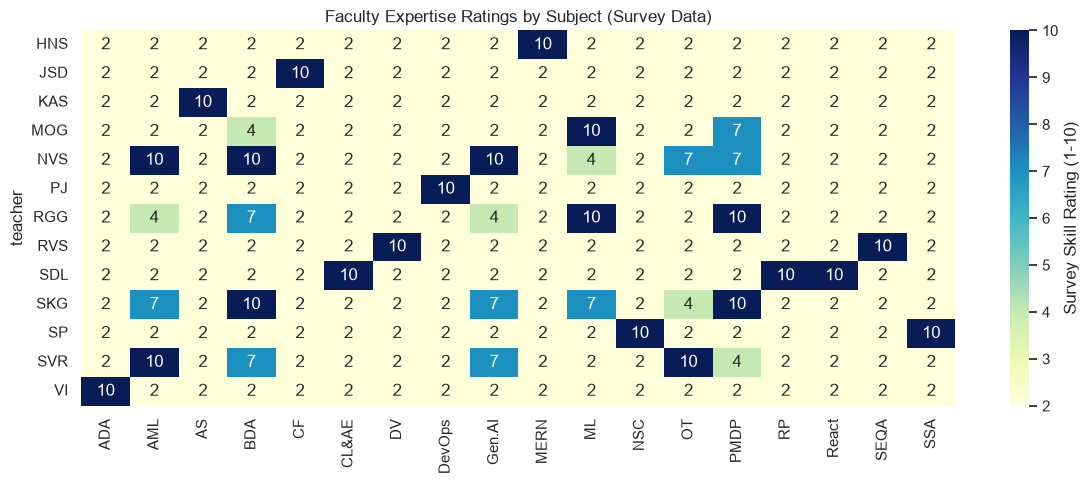

In [3]:
plt.figure(figsize=(12, 5))
sns.heatmap(df_skills, annot=True, cmap="YlGnBu", cbar_kws={"label": "Survey Skill Rating (1-10)"})
plt.title("Faculty Expertise Ratings by Subject (Survey Data)")
plt.tight_layout()
plt.savefig("figs/expertise_heatmap.png", dpi=160)
plt.show()


## 3. Mathematical Cost Formulation & Step-by-Step Viva Hand-Worked Demo
Examiners often request hand-worked verification of the Kuhn-Munkres reduction steps:
1. **Row Reduction:** Subtract row minimum from each row.
2. **Column Reduction:** Subtract column minimum from each column.
3. **Independent Matching:** Optimal matching on zeros.


In [4]:
C_base = core.compute_base_cost_matrix(courses, teachers, df_skills, df_prefs, w_skill=2.0, w_pref=0.5)

# Step-by-step 5x5 slice
viva_dict = core.get_viva_step_by_step_matrices(
    C_base[:5, :5],
    row_labels=[f"{courses.iloc[i].course_id} ({courses.iloc[i].subject})" for i in range(5)],
    col_labels=[f"Prof. {t}" for t in teachers[:5]]
)
print("Step 0: Initial 5x5 Cost Matrix Slice:")
display(viva_dict["step0_initial"])

print("\nStep 1: Row-Reduced Matrix:")
display(viva_dict["step1_row_reduced"])

print("\nStep 2: Column-Reduced Matrix:")
display(viva_dict["step2_col_reduced"])

print("\nOptimal Independent Matching on 5x5 Slice:")
display(viva_dict["optimal_matching"])


Step 0: Initial 5x5 Cost Matrix Slice:


,Prof. HNS,Prof. JSD,Prof. KAS,Prof. MOG,Prof. NVS
C01 (ADA),17.0,17.0,17.0,18.0,19.5
C02 (ADA),17.0,17.0,17.0,18.0,19.5
C03 (ADA),17.0,17.0,17.0,18.0,19.5
C04 (AML),17.5,17.5,17.5,18.5,0.5
C05 (AML),17.5,17.5,17.5,18.5,0.5



Step 1: Row-Reduced Matrix:


,Prof. HNS,Prof. JSD,Prof. KAS,Prof. MOG,Prof. NVS
C01 (ADA),0.0,0.0,0.0,1.0,2.5
C02 (ADA),0.0,0.0,0.0,1.0,2.5
C03 (ADA),0.0,0.0,0.0,1.0,2.5
C04 (AML),17.0,17.0,17.0,18.0,0.0
C05 (AML),17.0,17.0,17.0,18.0,0.0



Step 2: Column-Reduced Matrix:


,Prof. HNS,Prof. JSD,Prof. KAS,Prof. MOG,Prof. NVS
C01 (ADA),0.0,0.0,0.0,0.0,2.5
C02 (ADA),0.0,0.0,0.0,0.0,2.5
C03 (ADA),0.0,0.0,0.0,0.0,2.5
C04 (AML),17.0,17.0,17.0,17.0,0.0
C05 (AML),17.0,17.0,17.0,17.0,0.0



Optimal Independent Matching on 5x5 Slice:


,Course,Assigned Faculty,Original Cost
0,C01 (ADA),Prof. HNS,17.0
1,C02 (ADA),Prof. JSD,17.0
2,C03 (ADA),Prof. KAS,17.0
3,C04 (AML),Prof. NVS,0.5
4,C05 (AML),Prof. MOG,18.5


## 4. Multi-Model Optimization Execution
Running Raw Hungarian, Repaired Hungarian, MILP, and GA on identical data.


In [5]:
comp_df, store = core.run_comprehensive_comparison(
    courses, teachers, df_tt, C_base, clash_pairs,
    lam=2.0, cap=4, max_weekly_periods=28.0,
    ga_pop_size=100, ga_generations=120, seed=42
)
display(comp_df)


,Method,Total Assignment Cost,Base Cost (Skill+Pref),Workload Penalty (λ),Assigned Courses,Unassigned Courses,Timetable Clashes,Capacity Violations,Weekly Period Violations,Execution Time (s),Feasibility,Optimality Status
0,Current Timetable,99.5,25.5,74.0,36,0,0,0,21.0,0.000,Infeasible,Manual / Legacy Baseline
1,Raw Hungarian (Kuhn-Munkres),97.5,25.5,72.0,36,0,4,0,19.0,0.029,Infeasible,Exact on Cost (Unconstrained Timetable)
2,Hungarian + Conflict Repair,97.5,25.5,72.0,36,0,0,0,18.0,0.069,Infeasible,Near-Optimal (Greedy Conflict Repair)
3,Mixed-Integer Linear Program (MILP),179.5,111.5,68.0,36,0,0,0,0.0,11.145,Feasible,Proven Globally Optimal (HiGHS MIP)
4,Genetic Algorithm (GA),207.0,139.0,68.0,36,0,0,0,0.0,2.318,Feasible,Feasible Metaheuristic (Approximate)


## 5. Visual Comparison: Cost, Clashes, and Runtime


C:\Users\Administrator\AppData\Local\Temp\ipykernel_1032\3900641936.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=comp_df, x="Method", y="Total Assignment Cost", ax=axes[0], palette="Blues_d")
C:\Users\Administrator\AppData\Local\Temp\ipykernel_1032\3900641936.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=comp_df, x="Method", y="Timetable Clashes", ax=axes[1], palette="Reds_d")
C:\Users\Administrator\AppData\Local\Temp\ipykernel_1032\3900641936.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=comp_df, x="Method

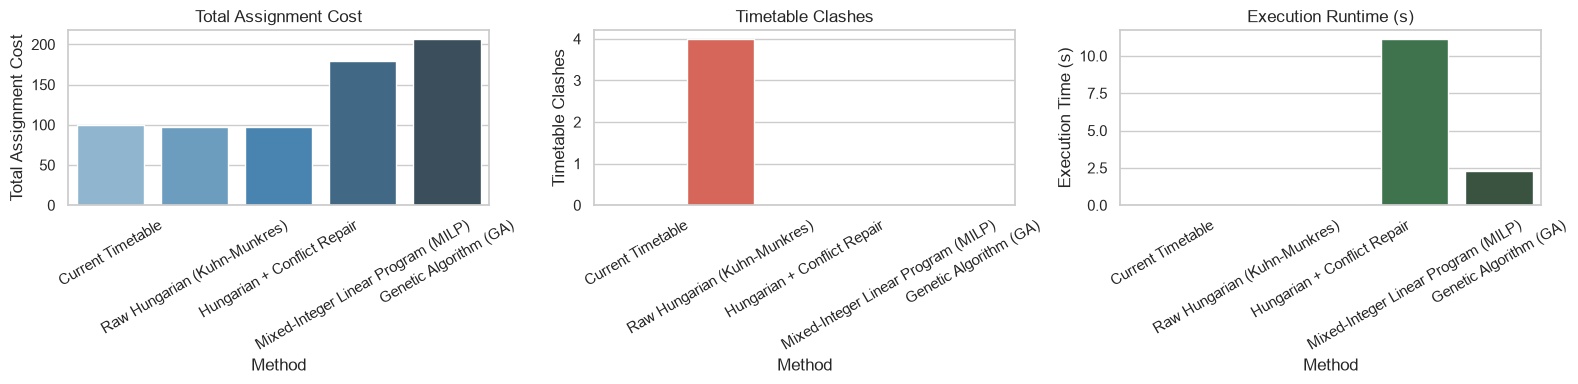

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.barplot(data=comp_df, x="Method", y="Total Assignment Cost", ax=axes[0], palette="Blues_d")
axes[0].tick_params(axis="x", rotation=30)
axes[0].set_title("Total Assignment Cost")

sns.barplot(data=comp_df, x="Method", y="Timetable Clashes", ax=axes[1], palette="Reds_d")
axes[1].tick_params(axis="x", rotation=30)
axes[1].set_title("Timetable Clashes")

sns.barplot(data=comp_df, x="Method", y="Execution Time (s)", ax=axes[2], palette="Greens_d")
axes[2].tick_params(axis="x", rotation=30)
axes[2].set_title("Execution Runtime (s)")

plt.tight_layout()
plt.savefig("figs/cost_comparison.png", dpi=160)
plt.show()


## 6. Faculty Workload Contact Hours Analysis


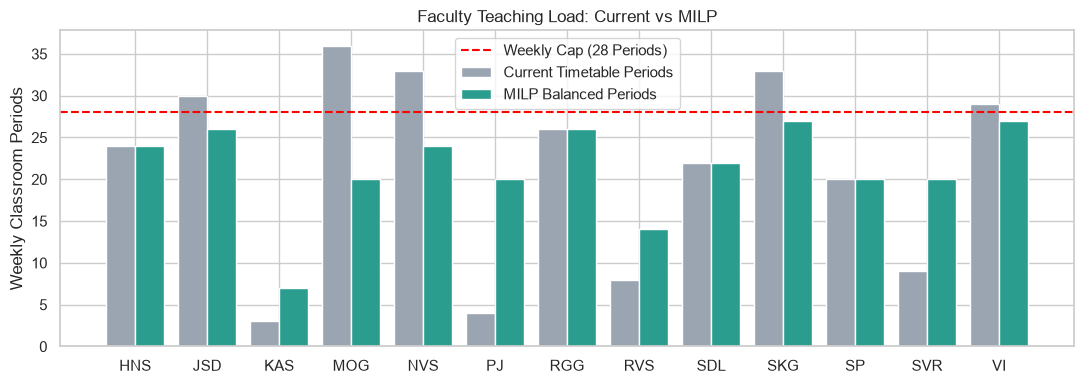

In [7]:
milp_df = store["milp"]["dataframe"]
cur_periods = df_tt.groupby("teacher").size().reindex(teachers, fill_value=0)
milp_periods = milp_df.groupby("assigned_teacher")["periods"].sum().reindex(teachers, fill_value=0)

plt.figure(figsize=(11, 4))
x = np.arange(len(teachers))
plt.bar(x - 0.2, cur_periods, width=0.4, label="Current Timetable Periods", color="#9aa5b1")
plt.bar(x + 0.2, milp_periods, width=0.4, label="MILP Balanced Periods", color="#2a9d8f")
plt.xticks(x, teachers)
plt.ylabel("Weekly Classroom Periods")
plt.title("Faculty Teaching Load: Current vs MILP")
plt.axhline(28, color="red", linestyle="--", label="Weekly Cap (28 Periods)")
plt.legend()
plt.tight_layout()
plt.savefig("figs/workload.png", dpi=160)
plt.show()


## 7. Multi-Parameter Sensitivity Analysis


,Parameter,Value,Total Cost,Base Cost,Courses Moved vs Current,Max Teacher Course Load,Timetable Clashes,Status
0,lambda,0.0,111.0,111.0,6,4,0,Optimal/Feasible
1,lambda,1.0,145.5,111.5,6,4,0,Optimal/Feasible
2,lambda,2.0,179.5,111.5,6,4,0,Optimal/Feasible
3,lambda,3.0,213.5,111.5,6,4,0,Optimal/Feasible
4,lambda,5.0,281.5,111.5,6,4,0,Optimal/Feasible
5,lambda,8.0,383.5,111.5,6,4,0,Optimal/Feasible


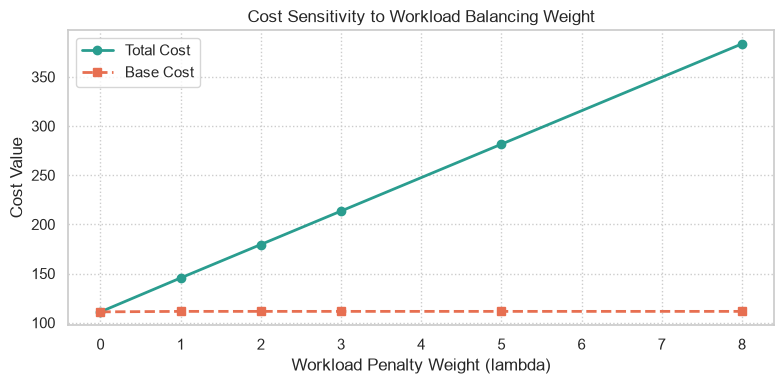

In [8]:
sens_df = core.run_sensitivity_analysis(
    courses, teachers, df_tt, df_skills, df_prefs, clash_pairs,
    parameter="lambda", values=[0.0, 1.0, 2.0, 3.0, 5.0, 8.0],
    default_lam=2.0, default_cap=4, default_max_periods=28.0, solver="milp"
)
display(sens_df)

plt.figure(figsize=(8, 4))
plt.plot(sens_df["Value"], sens_df["Total Cost"], "o-", color="#2a9d8f", label="Total Cost", lw=2)
plt.plot(sens_df["Value"], sens_df["Base Cost"], "s--", color="#e76f51", label="Base Cost", lw=2)
plt.xlabel("Workload Penalty Weight (lambda)")
plt.ylabel("Cost Value")
plt.title("Cost Sensitivity to Workload Balancing Weight")
plt.legend()
plt.grid(True, linestyle=":")
plt.tight_layout()
plt.savefig("figs/sensitivity.png", dpi=160)
plt.show()


## 8. What-If Teacher Absence Simulation (Leave-One-Out)


In [9]:
absence_records = []
for absent_t in ["NVS", "MOG", "JSD"]:
    abs_res = core.simulate_teacher_absence(
        courses, teachers, df_tt, df_skills, df_prefs, absent_t, clash_pairs,
        solver="milp", max_weekly_periods=32.0
    )
    realloc_summary = "; ".join([f"{r.course_id} ({r.subject}) -> {r.reallocated_teacher}" for r in abs_res["reallocated_courses"].itertuples()])
    absence_records.append({
        "Absent Teacher": absent_t,
        "Total Cost": round(abs_res["total_cost"], 2),
        "Avg Expertise": abs_res["avg_expertise"],
        "Clashes": abs_res["clashes"],
        "Reallocated Courses": realloc_summary
    })

display(pd.DataFrame(absence_records))


,Absent Teacher,Total Cost,Avg Expertise,Clashes,Reallocated Courses
0,NVS,192.0,8.94,0,C04 (AML) -> SVR; C08 (BDA) -> MOG; C18 (Gen.A...
1,MOG,185.0,9.11,0,C23 (ML) -> PJ; C24 (ML) -> KAS; C25 (ML) -> PJ
2,JSD,214.5,8.67,0,C09 (CF) -> RVS; C10 (CF) -> KAS; C11 (CF) -> ...
